# Machine Learning: Exercise session 09

In this exercise session we will focus on support vector machines (SVM), and boosting for the practical parts.

The theoretical exercise deals with kernels used in SVM.

## 1. SVM

In [35]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
%matplotlib inline
import numpy as np
import pandas as pd

In [36]:
def plot_dataset(X, y, axes=[-1.5, 2.5, -1, 1.5]):
    plt.plot(X[:, 0][y==0], X[:, 1][y==0], "bs")
    plt.plot(X[:, 0][y==1], X[:, 1][y==1], "g^")
    plt.axis(axes)
    plt.grid(True, which='both')
    plt.xlabel(r"$x_1$", fontsize=20)
    plt.ylabel(r"$x_2$", fontsize=20, rotation=0)

def plot_predictions(clf, axes=[-1.5, 2.5, -1, 1.5]):
    x0s = np.linspace(axes[0], axes[1], 100)
    x1s = np.linspace(axes[2], axes[3], 100)
    x0, x1 = np.meshgrid(x0s, x1s)
    X = np.c_[x0.ravel(), x1.ravel()]
    y_pred = clf.predict(X).reshape(x0.shape)
    y_decision = clf.decision_function(X).reshape(x0.shape)
    plt.contourf(x0, x1, y_pred, cmap=plt.cm.brg, alpha=0.2)
    plt.contourf(x0, x1, y_decision, cmap=plt.cm.brg, alpha=0.1)

* We will use a toy dataset for binary classification in which the data points are shaped as two interleaving half circles. 
Generate the dataset using the `make_moons()` function from `sklearn.datasets` with `n_samples = 100`, `noise = 0.15`, and `random_state = 42`.

In [37]:

from sklearn.datasets import make_moons

X, y = make_moons(
    n_samples=100,
    noise=0.15,
    random_state=42
)

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (100, 2)
y shape: (100,)


* Plot the data using the function `plot_dataset`.

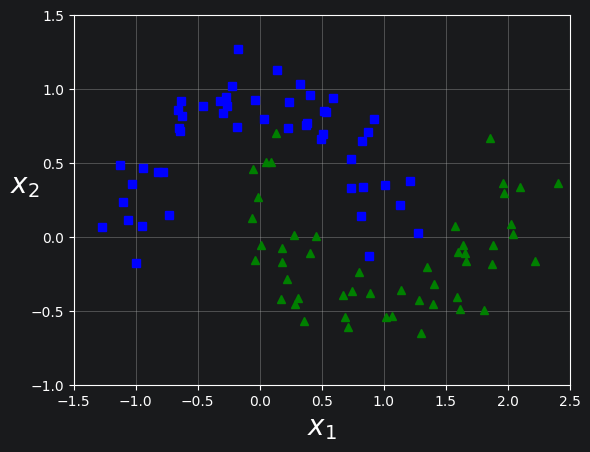

In [38]:

plot_dataset(X, y)


We start by fitting a linear SVM. 

* Create a pipeline to scale the features, and then train a linear SVM model (using the class `LinearSVC` with `C=1` and the hinge loss function).

_Hint_: recall that SVM are sensitive to feature scaling, so it's good pratcice to scale the features before fitting an SVM.

In [39]:
from sklearn.svm import LinearSVC
from sklearn.model_selection import KFold, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

svm_clf = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', LinearSVC(C=1, loss="hinge"))
])

svm_clf.fit(X,y)

Pipeline(steps=[('scaler', StandardScaler()),
                ('svm', LinearSVC(C=1, loss='hinge'))])

* Using the functions `plot_dataset` and `plot_predictions` plot the fitted SVM.

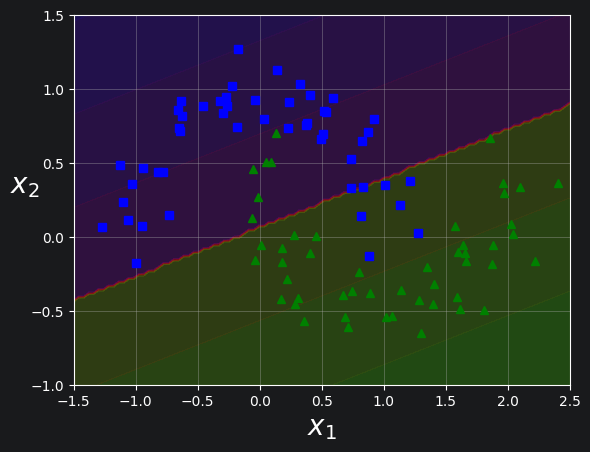

In [40]:
plot_predictions(svm_clf)
plot_dataset(X, y)


Although linear SVM classifiers are efficient and work surprisingly well in many cases, you can see that this dataset is not even close to being linearly separable. One approach to handling nonlinear datasets is to add more features, such as polynomial features; in some cases this can result in a linearly separable dataset.

* To implement this idea using Scikit-Learn, create a `Pipeline` containing a `PolynomialFeatures` with `degree = 3`, followed by a `StandardScaler` and a `LinearSVC` with `C=1` and hinge loss.

In [41]:
from sklearn.preprocessing import PolynomialFeatures

polynomial_svm_clf = Pipeline([
    ("poly_features", PolynomialFeatures(degree=3)),
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(C=1, loss="hinge"))
])

polynomial_svm_clf.fit(X, y)


Pipeline(steps=[('poly_features', PolynomialFeatures(degree=3)),
                ('scaler', StandardScaler()),
                ('svm', LinearSVC(C=1, loss='hinge'))])

* Plot the dataset and the predictions trying different degrees in the `PolymonialFeatures` and different values of the tuning parameter `C`. What are the effects of these tuning parameters?

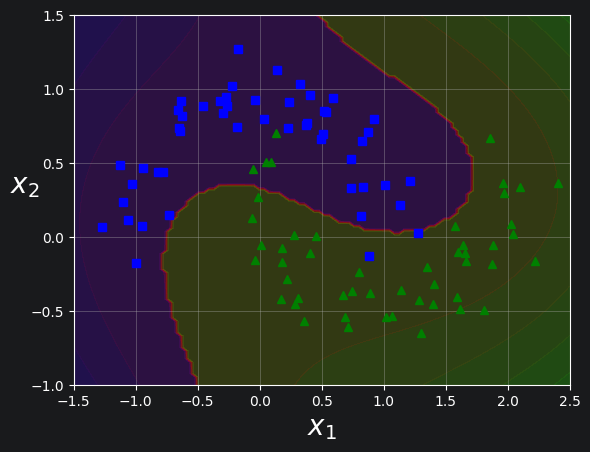

In [42]:
plot_predictions(polynomial_svm_clf)
plot_dataset(X, y)

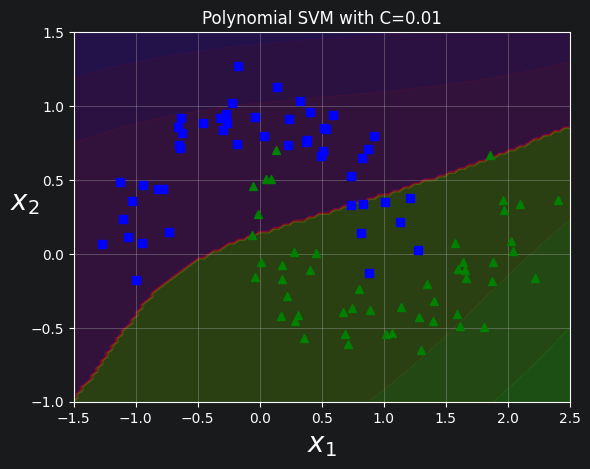

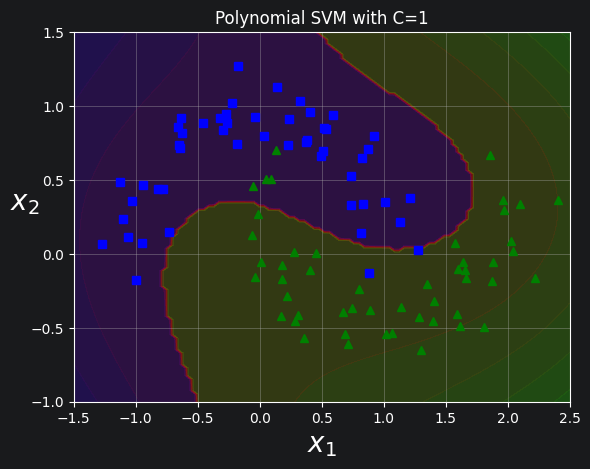

/Users/helianferraris/Desktop/Machine Learning/Exercise_09/.venv/lib/python3.9/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


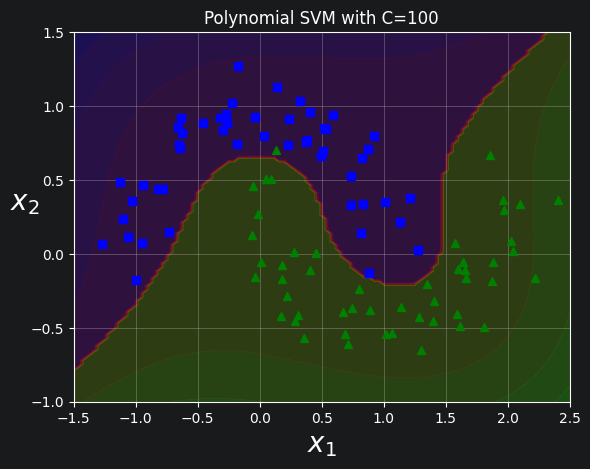

In [43]:

for C in [0.01, 1, 100]:
    polynomial_svm_clf = Pipeline([
        ("poly_features", PolynomialFeatures(degree=3)),
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(C=C, loss="hinge"))
    ])

    polynomial_svm_clf.fit(X, y)

    plt.figure()
    plot_predictions(polynomial_svm_clf)
    plot_dataset(X, y)
    plt.title(f"Polynomial SVM with C={C}")
    plt.show()


* Another useful transformation to apply to the features is the radial basis function. Create a `Pipeline` containing a `RBFSampler` from `sklearn.kernel_approximation`, followed by a `StandardScaler` and a `LinearSVC` with `C=0.1` and hinge loss. 

_Hint_: The `RBFSampler` has a tuning parameter `gamma`. What is its role?

In [44]:

from sklearn.kernel_approximation import RBFSampler

rbf_svm_clf = Pipeline([
    ("rbf_features", RBFSampler(gamma=1, random_state=42)),
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(C=0.1, loss="hinge"))
])

rbf_svm_clf.fit(X, y)


Pipeline(steps=[('rbf_features', RBFSampler(gamma=1, random_state=42)),
                ('scaler', StandardScaler()),
                ('svm', LinearSVC(C=0.1, loss='hinge'))])

* Plot the dataset and the predictions trying different `gamma` in the `RBFSampler` and different values of the tuning parameter `C`. What are the effects of these tuning parameters?

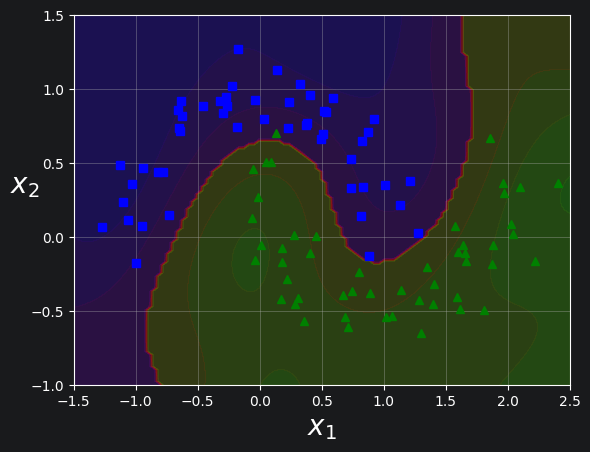

In [45]:
plot_predictions(rbf_svm_clf)
plot_dataset(X, y)

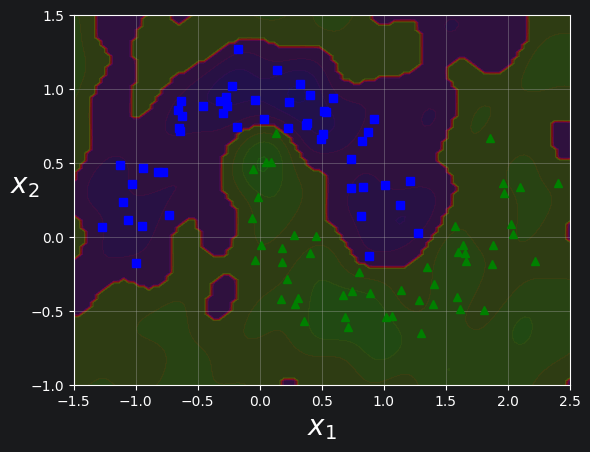

In [46]:
rbf_svm_clf = Pipeline([
    ("rbf_features", RBFSampler(gamma=10, random_state=42)),
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(C=10, loss="hinge"))
])

rbf_svm_clf.fit(X, y)

plot_predictions(rbf_svm_clf)
plot_dataset(X, y)

gamma=10: The RBF transformation can represent more localized patterns.



C=10: We reduced regularization, so the SVM penalizes margin violations more heavily.

As a result, the model found a decision boundary that correctly separates all the training observations.

But 100% training accuracy does not necessarily mean the model is better at predicting new observations.

So far, we tried to solve the problem of non linear decision boundary by performing explicit feature transformations (i.e., adding polynomial features or radial basis function). Another way to do this, is by using the _kernel trick_. 
The kernel trick makes it possible to get the same result as if you performed feature transformations, without actually having to add new features.

__Remark__: Using the kernel trick is advisable only for small to medium-sized datasets.
It scales well with the number of features, especially with sparse features (i.e., when each instance has few nonzero features).
When the number of observations gets large (e.g., hundreds of thousands of instances), using the kernel trick is _very_ slow. In such a case, one can still use the approach above for a more reasonable fitting time, i.e., first tranforming features and then applying linear SVM.


* Create a `Pipeline` containing a `StandardScaler` and a `SVC` with `kernel="poly"`, `coef0=1`, `degree=3`, and `C=1`. Fit the pipeline and plot the results as above.

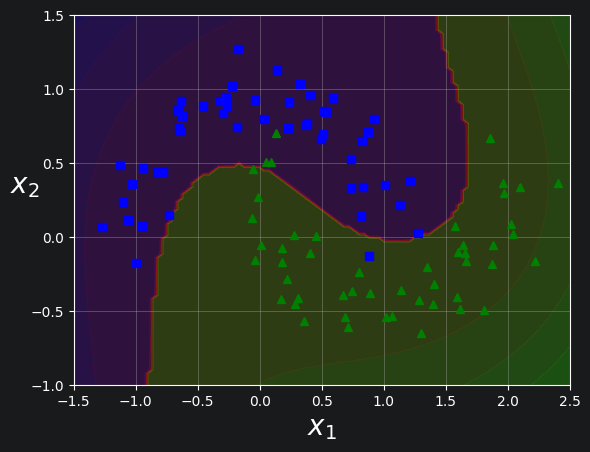

In [47]:
from sklearn.svm import SVC

poly_kernel_svm_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel = 'poly', degree =3, coef0=1,C=1))
])

poly_kernel_svm_clf.fit(X, y)

plot_predictions(poly_kernel_svm_clf)
plot_dataset(X, y)

* Create a `Pipeline` containing a `StandardScaler` and a `SVC` with `kernel="rbf"`, `gamma=5`, and `C=1`. Fit the pipeline and plot the results as above.

__Remark__: Notice that the results that you obtain here do not match exactly with `RBFSampler`. In fact, the `RBFSampler` constructs an _approximate_ mapping for the radial basis function kernel.

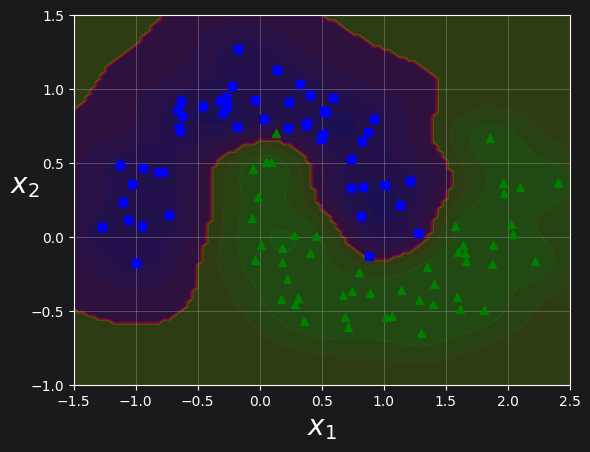

In [48]:
rbf_kernel_svm_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel = 'rbf', gamma=5, C=1))
])

rbf_kernel_svm_clf.fit(X, y)

plot_predictions(rbf_kernel_svm_clf)
plot_dataset(X, y)

* For each pipelines created above (except for the simple linear SVM) run a `GridSearchCV` with 10 folds and with the relevant hyperparameters. Rembember to create a common `folds` object.

In [49]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

folds = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

polynomial_svm_clf.set_params(svm__max_iter=100000)
rbf_svm_clf.set_params(svm__max_iter=100000)

# PolynomialFeatures + LinearSVC:

param_grid_poly_linearSVC = {
    "poly_features__degree": [2, 3, 5],
    "svm__C": [0.01, 0.1, 1,10]
}

# Define grid search CV
grid_search_poly_linearSVC = GridSearchCV(
    estimator=polynomial_svm_clf,
    param_grid=param_grid_poly_linearSVC,
    cv=folds,
    scoring='accuracy'
)

# RBFSampler + LinearSVC:

param_grid_rbf_linearSVC = {
    "rbf_features__gamma": [0.01, 0.1, 1, 10],
    "svm__C": [0.01, 0.1, 1,10]
}

# Define grid search CV
grid_search_rbf_linearSVC = GridSearchCV(
    estimator=rbf_svm_clf,
    param_grid=param_grid_rbf_linearSVC,
    cv=folds,
    scoring='accuracy'
)

# Fitting GridSearchCV objects:

grid_search_poly_linearSVC.fit(X, y)
grid_search_rbf_linearSVC.fit(X, y)

print("PolynomialFeatures + LinearSVC:")
print(grid_search_poly_linearSVC.best_params_)
print(grid_search_poly_linearSVC.best_score_)

print("RBFSampler + LinearSVC:")
print(grid_search_rbf_linearSVC.best_params_)
print(grid_search_rbf_linearSVC.best_score_)


/Users/helianferraris/Desktop/Machine Learning/Exercise_09/.venv/lib/python3.9/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/helianferraris/Desktop/Machine Learning/Exercise_09/.venv/lib/python3.9/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/helianferraris/Desktop/Machine Learning/Exercise_09/.venv/lib/python3.9/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


PolynomialFeatures + LinearSVC:
{'poly_features__degree': 3, 'svm__C': 10}
0.95
RBFSampler + LinearSVC:
{'rbf_features__gamma': 10, 'svm__C': 0.01}
0.9800000000000001


In [50]:

# Polynomial features (kernel trick):

# Define parameter grid
param_grid_poly = {
    'svm__degree': [2,3,5],
    "svm__C": [0.01, 0.1, 1,10],
    "svm__coef0": [0, 1, 10]
}

# Define grid search CV
grid_search_poly = GridSearchCV(
    estimator=poly_kernel_svm_clf,
    param_grid=param_grid_poly,
    cv=folds,
    scoring='accuracy'
)

# RBF (kernel trick):

# Define parameter grid
param_grid_rbf = {
    "svm__C": [0.01, 0.1, 1,10],
    "svm__gamma": [0.01, 0.1, 1]
}

# Define grid search CV
grid_search_rbf = GridSearchCV(
    estimator=rbf_kernel_svm_clf,
    param_grid=param_grid_rbf,
    cv=folds,
    scoring='accuracy'
)

# Fitting GridSearchCV objects:

grid_search_poly.fit(X, y)
grid_search_rbf.fit(X, y)


GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svm', SVC(C=1, gamma=5))]),
             param_grid={'svm__C': [0.01, 0.1, 1, 10],
                         'svm__gamma': [0.01, 0.1, 1]},
             scoring='accuracy')

In [51]:
print("Polynomial kernel:")
print(grid_search_poly.best_params_) # hyperparameter combination with the highest mean validation score
print(grid_search_poly.best_score_) # mean cross-validation accuracy.

print("RBF kernel:")
print(grid_search_rbf.best_params_)
print(grid_search_rbf.best_score_)

Polynomial kernel:
{'svm__C': 0.01, 'svm__coef0': 10, 'svm__degree': 5}
0.95
RBF kernel:
{'svm__C': 10, 'svm__gamma': 1}
0.9800000000000001


* Create a new test dataset and evaluate the best models.

In [52]:
X_test, y_test = make_moons(
    n_samples=100,
    noise=0.15,
    random_state=123
)

# Retrieve our best models:

best_poly_kernel = grid_search_poly.best_estimator_
best_rbf_kernel = grid_search_rbf.best_estimator_

best_poly_linearSVC = grid_search_poly_linearSVC.best_estimator_
best_rbf_linearSVC = grid_search_rbf_linearSVC.best_estimator_

**Evaluate the best models**

In [53]:
from sklearn.metrics import accuracy_score

# Polynomial-kernel SVM:
# Predict the labels of the new observations
y_pred = best_poly_kernel.predict(X_test)

# Compare predictions with the true labels
test_accuracy = accuracy_score(y_test, y_pred)

print("Polynomial-kernel SVM test accuracy:", test_accuracy)

# RBF-kernel SVM
y_pred_rbf = best_rbf_kernel.predict(X_test)

test_accuracy_rbf = accuracy_score(y_test, y_pred_rbf)

print("RBF-kernel SVM test accuracy:", test_accuracy_rbf)

# RBFSampler + LinearSVC:
y_pred_rbf_sampler = best_rbf_linearSVC.predict(X_test)

test_accuracy_rbf_sampler = accuracy_score(y_test, y_pred_rbf_sampler)

print("RBFSampler test accuracy:", test_accuracy_rbf_sampler)

# PolynomialFeatures + LinearSVC:
y_pred_polyfeatures = best_poly_linearSVC.predict(X_test)

test_accuracy_polyfeatures = accuracy_score(y_test, y_pred_polyfeatures)

print("PolynomialFeatures test accuracy:", test_accuracy_polyfeatures)


Polynomial-kernel SVM test accuracy: 0.96
RBF-kernel SVM test accuracy: 0.96
RBFSampler test accuracy: 0.99
PolynomialFeatures test accuracy: 0.95


## 2. Boosting
Boosting refers to any Ensemble method that can combine several weak learners into a strong learner. The general idea of most boosting methods is to train predictors sequentially, each trying to correct its predecessor.


* Let us start by generating some synthetic dataset.

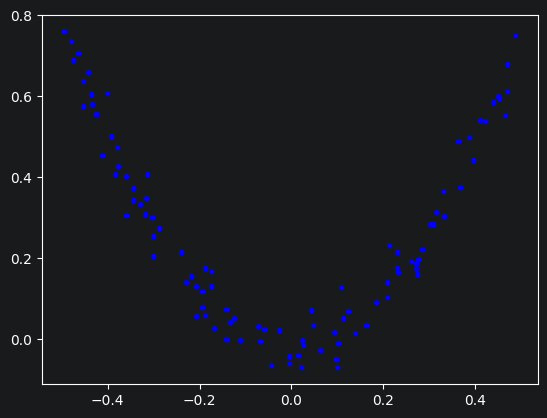

In [67]:
np.random.seed(42)
X = np.random.rand(100, 1) - 0.5
y = 3 * X[:, 0] ** 2 + 0.05 * np.random.randn(100)

plt.plot(X[:, 0], y, "b.");

Gradient Boosting works by sequentially adding predictors to an ensemble, each one correcting its predecessor. This method tries to fit the new predictor to the residual errors made by the previous predictor.
Let’s go through a simple regression example, using Decision Trees as the base predictors. This is called Gradient Tree Boosting, or Gradient Boosted Regression Trees (GBRT). 

* First, let’s fit a `DecisionTreeRegressor` with `max_depth=2` on the training set.

In [55]:

from sklearn.tree import DecisionTreeRegressor

# First tree:
tree_reg1 = DecisionTreeRegressor(max_depth=2)

tree_reg1.fit(X, y)


DecisionTreeRegressor(max_depth=2)

In [68]:
tree_reg1.get_n_leaves()

np.int64(4)

* Next, let's fit another `DecisionTreeRegressor` with `max_depth=2` on the _residual_ errors made by the first model. Fill in the `??`.

In [56]:
# Train the second tree:

# Calculate residual errors from the first tree
y2 = y - tree_reg1.predict(X)

# Train a second tree on these residuals
tree_reg2 = DecisionTreeRegressor(max_depth=2)
tree_reg2.fit(X, y2)

DecisionTreeRegressor(max_depth=2)

* Now, let's train a third predictor on the residual errors made by the second model. Fill in the `??`.

In [57]:
y3 =  y - (tree_reg1.predict(X) + tree_reg2.predict(X))
tree_reg3 = DecisionTreeRegressor(max_depth=2)
tree_reg3.fit(X, y3)

DecisionTreeRegressor(max_depth=2)

* At this point, we have an ensemble containing three tree predictions. We can make predictions on a new instance simply by adding up the predictions of all the trees. Fill in the ??

In [58]:
np.random.seed(1234)
X_test = np.random.rand(100, 1) - 0.5
y_pred = tree_reg1.predict(X_test) + tree_reg2.predict(X_test) + tree_reg3.predict(X_test)

* Now plot the residual and the esemble predictions using the function `plot_predictions`. Fill in the `??`.

In [59]:
def plot_predictions2(regressors, X, y, axes, style="r-", label=None, data_style="b.", data_label=None):
    x1 = np.linspace(axes[0], axes[1], 500)
    y_pred = sum(regressor.predict(x1.reshape(-1, 1)) for regressor in regressors)
    plt.plot(X[:, 0], y, data_style, label=data_label)
    plt.plot(x1, y_pred, style, linewidth=2, label=label)
    if label or data_label:
        plt.legend(loc="upper center", fontsize=16)
    plt.axis(axes)
    plt.xlabel(r"$x_1$", fontsize=14)
    plt.ylabel(r"$y$", fontsize=14, rotation=0)

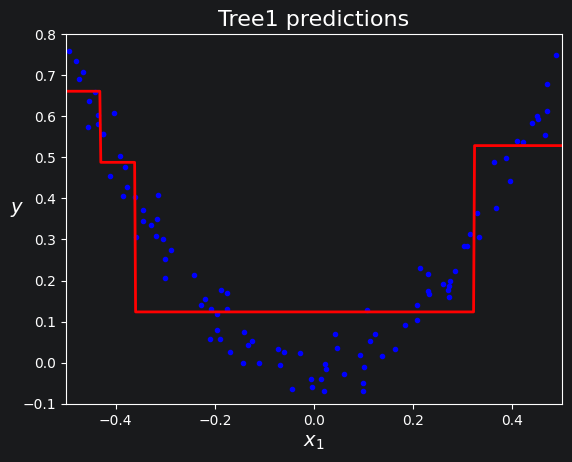

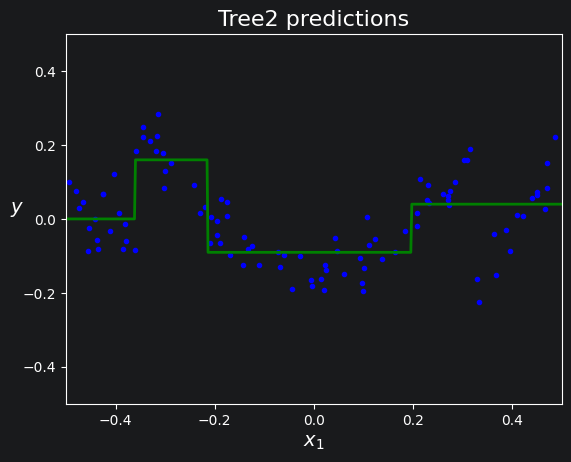

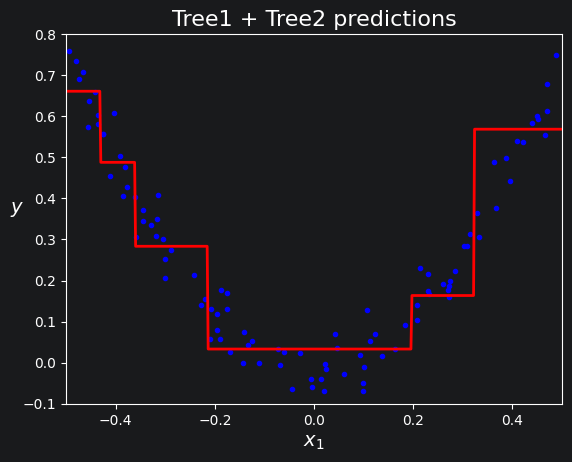

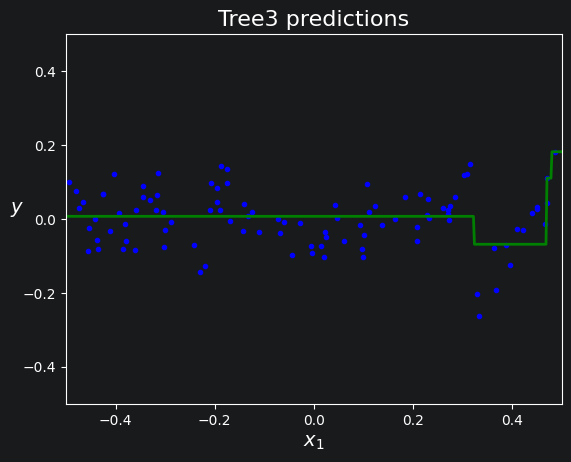

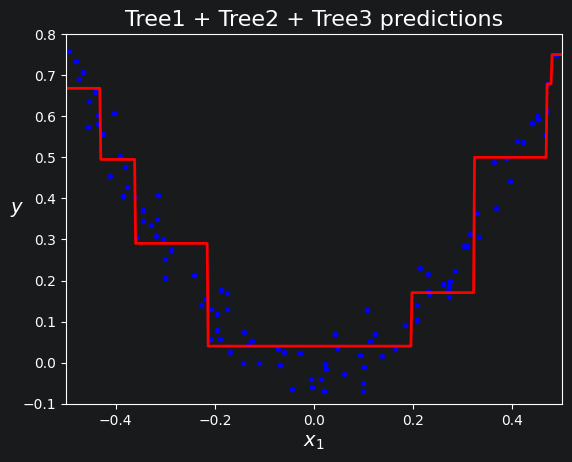

In [60]:
# Plot first predictor
plot_predictions2([tree_reg1], X, y, axes = [-0.5, 0.5, -0.1, 0.8])
plt.title("Tree1 predictions", fontsize=16)
plt.show()

# Plot second predictor alone on the residuals
plot_predictions2([tree_reg2], X, y2, axes = [-0.5, 0.5, -0.5, 0.5], style="g-");
plt.title("Tree2 predictions", fontsize=16)
plt.show()

# Plot the first and second predictor together
plot_predictions2([tree_reg1, tree_reg2], X, y, axes = [-0.5, 0.5, -0.1, 0.8])
plt.title("Tree1 + Tree2 predictions", fontsize=16)
plt.show()

# Plot the third predictor alone on the residuals
plot_predictions2([tree_reg3], X, y3, axes = [-0.5, 0.5, -0.5, 0.5], style="g-");
plt.title("Tree3 predictions", fontsize=16)
plt.show()

# Plot all three prectors together
plot_predictions2([tree_reg1,tree_reg2,tree_reg3], X, y, axes = [-0.5, 0.5, -0.1, 0.8])
plt.title("Tree1 + Tree2 + Tree3 predictions", fontsize=16)
plt.show()

A simpler way to train GBRT ensembles is to use Scikit-Learn’s `GradientBoostingRegressor` class.
Similarly to `RandomForestRegressor`, it has hyperparameters to control the growth of Decision Trees (e.g., `max_depth`, `min_samples_leaf`), as well as hyperparameters to control the ensemble training, such as the number of trees (`n_estimators`) and the shrinkage parameter (`learning_rate`).

* Fit a `GradientBoostingRegressor` with `max_depth=2`, `n_estimators=3`, and `learning_rate=1.0` and plot the predictions.

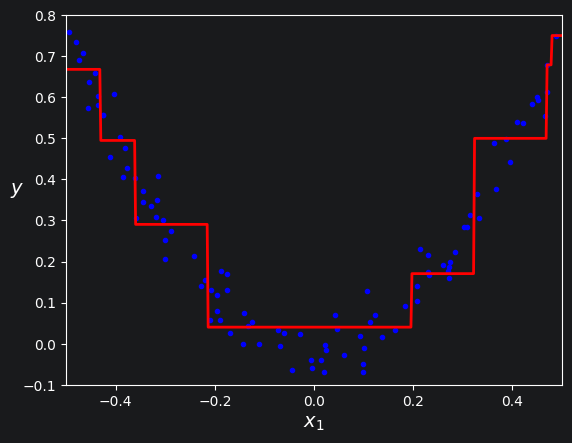

In [61]:
from sklearn.ensemble import GradientBoostingRegressor

gbrt = GradientBoostingRegressor(
    max_depth=2,
    n_estimators=3,
    learning_rate=1.0
)

gbrt.fit(X,y)

plot_predictions2([gbrt], X, y, axes=[-0.5, 0.5, -0.1, 0.8])

#gbrt.predict(X_test) # automatically combines the contributions of the boosting stages

The `learning_rate` hyperparameter scales the contribution of each tree. If you set it to a low value, such as 0.01 or 0.001, you will need more trees in the ensemble to fit the training set, but the predictions will usually generalize better. This is a regularization technique called shrinkage.

* Repeat the fitting and plotting above with different values for `n_estimators` and `learning_rate`.

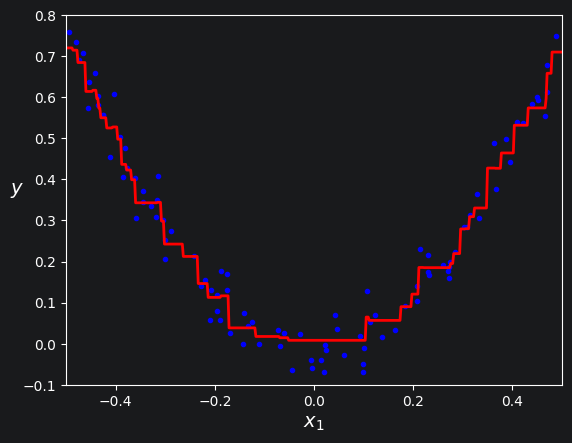

In [69]:
from sklearn.ensemble import GradientBoostingRegressor

gbrt = GradientBoostingRegressor(
    max_depth=2,
    n_estimators=500,
    learning_rate=0.01
)
gbrt.fit(X,y)
plot_predictions2([gbrt], X, y, axes=[-0.5, 0.5, -0.1, 0.8])


* We now apply boosting to the `Heart_ISL.csv` dataset. Recall that this is a classification problem, therefore we need to use `GradientBoostingClassifier`. Fill in the `??`.

In [72]:
heart = pd.read_csv("Heart_ISL.csv",index_col=0).dropna().reset_index(drop=True)
heart = heart.astype({'ChestPain':'category', 'Thal':'category', 'AHD':'category'})
print("Original dataset shape:", heart.shape)
#heart.head()
X = pd.get_dummies(heart.drop("AHD", axis=1), drop_first=True)
y = heart["AHD"]

# Split into train and test dataset
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=40)

Original dataset shape: (297, 14)


In [73]:
# Fit boosting
from sklearn.ensemble import GradientBoostingClassifier

gbct = GradientBoostingClassifier(max_depth = 2, n_estimators = 1000, learning_rate = 0.01)
gbct.fit(X_train, y_train)
print('Test accuracy:')
gbct.score(X_test, y_test)

Test accuracy:


0.85

In [65]:
dir(gbct)

#  'feature_importances_'

['__abstractmethods__',
 '__annotations__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__iter__',
 '__le__',
 '__len__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__sklearn_clone__',
 '__sklearn_tags__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_abc_impl',
 '_build_request_for_signature',
 '_check_feature_names',
 '_check_initialized',
 '_check_n_features',
 '_clear_state',
 '_compute_partial_dependence_recursion',
 '_doc_link_module',
 '_doc_link_template',
 '_doc_link_url_param_generator',
 '_encode_y',
 '_estimator_type',
 '_fit_stage',
 '_fit_stages',
 '_get_default_requests',
 '_get_doc_link',
 '_get_loss',
 '_get_metadata_request',
 '_get_param_names',
 '_get_tags',
 '_init_state',
 '_is_fitted',

A better test score could be achieved using a cross-validated grid search to find the best values for the hyperparameters `max_depth`, `learning_rate` and `n_estimators`, as usual.

* Plot the variable importance by filling the `??`.

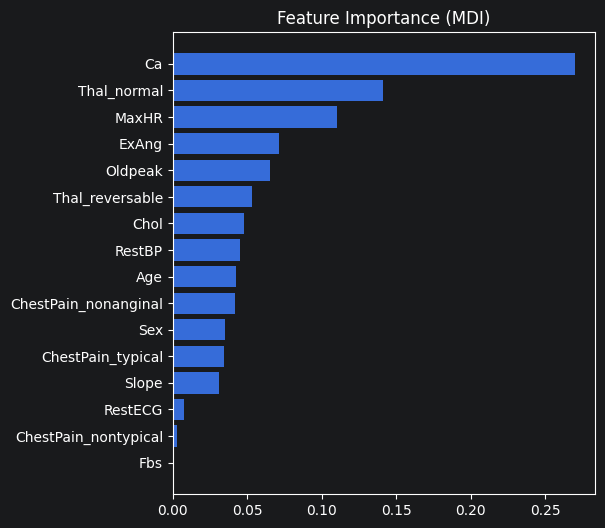

In [74]:
feature_importance = gbct.feature_importances_ # use dir(gbct) to find the right call
sorted_idx = np.argsort(feature_importance)
pos = np.arange(sorted_idx.shape[0]) + .5
fig = plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.barh(pos, feature_importance[sorted_idx], align='center')
plt.yticks(pos, np.array(list(X))[sorted_idx])
plt.title('Feature Importance (MDI)')
plt.show()

## 3. Theoretical Exercise: Kernels

Let $x_1, x_2 \in\mathbb R^3$ be observations in three dimensions (vectors). Consider the kernel function 
$k: \mathbb R^3 \times \mathbb R^3 \to \mathbb R$ defined as $k(x_1, x_2) = (1 + x_1^Tx_2)^2$.

With this exercise, we want to show that any valid kernel _implicitly_ represents
a dot product between two _transformed_ vectors.
In other words, for any
kernel $k$, one can find a transformation of the variables $\phi(x)$
(i.e., a feature transformation) such that $k(x_1, x_2) = \phi(x_1)^T\phi(x_2)$. 

This result helps a lot because one can represent a very high-dimensional feature
transformation without having to compute $\phi(x)$ explicitly (more about this in the
solutions).


1. Find a feature transformation $\phi(x)$, for $x\in\mathbb R^3$, such that 
$k(x_1, x_2) = \phi(x_1)^T \phi(x_2)$.

2. We know that a feature transformation is a function $\phi: \mathbb R^3 \to
\mathcal{X}$ that maps each observation $x\in\mathbb R^3$ to some point $\phi(x)$
in another space $\mathcal{X}$.
What is the dimension of such space $\mathcal{X}$?